# 08 - MediaPipe Preprocessing: La Gran Conversion

## Objetivo

Convertir TODOS los videos de WLASL30 a landmarks de MediaPipe.

**Input**: `video_id.mp4` (videos originales)

**Proceso**:
1. Cargar video MP4 original (no frames 224x224)
2. Extraer landmarks con MediaPipe Tasks API
3. Interpolar frames sin deteccion
4. Normalizar coordenadas

**Output**: `video_id.npy` - matriz `(T, 21, 3)` o `(T, 63)` aplanada

## Estadisticas esperadas

- Total videos WLASL30: 337 (245 train + 57 val + 35 test)
- 30 palabras/clases
- ~63 frames promedio por video

In [1]:
# Instalar dependencias
%pip install -q mediapipe opencv-python numpy tqdm


[notice] A new release of pip is available: 25.3 -> 26.0
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# ==========================================
# 1. IMPORTS Y CONFIGURACION
# ==========================================
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
import urllib.request
import os
import cv2
import numpy as np
import json
from pathlib import Path
from tqdm import tqdm
from typing import List, Tuple, Dict, Optional
import warnings
warnings.filterwarnings('ignore')

print(f"MediaPipe version: {mp.__version__}")

MediaPipe version: 0.10.32


In [3]:
# ==========================================
# 2. CONFIGURACION DE RUTAS
# ==========================================

# Rutas de entrada
WLASL30_ROOT = Path("/home/fransando/Dev/tfg-sign-language-recognition/06_datasets/wlasl/processed/wlasl30")
RAW_VIDEOS_DIR = Path("/home/fransando/Dev/tfg-sign-language-recognition/06_datasets/wlasl/raw/kaggle_wlasl/videos")

# Ruta de salida para landmarks
OUTPUT_ROOT = Path("/home/fransando/Dev/tfg-sign-language-recognition/06_datasets/wlasl/landmarks/wlasl30")

# Configuracion de procesamiento
MAX_FRAMES = 64  # Maximo frames por video (igual que en entrenamiento)
MIN_DETECTION_RATE = 0.3  # Minimo 30% de frames con deteccion para aceptar video

# Verificar rutas
print(f"WLASL30 metadata: {WLASL30_ROOT / 'metadata.json'}")
print(f"  Existe: {(WLASL30_ROOT / 'metadata.json').exists()}")
print(f"\nVideos raw: {RAW_VIDEOS_DIR}")
print(f"  Existe: {RAW_VIDEOS_DIR.exists()}")
print(f"\nOutput: {OUTPUT_ROOT}")

WLASL30 metadata: /home/fransando/Dev/tfg-sign-language-recognition/06_datasets/wlasl/processed/wlasl30/metadata.json
  Existe: True

Videos raw: /home/fransando/Dev/tfg-sign-language-recognition/06_datasets/wlasl/raw/kaggle_wlasl/videos
  Existe: True

Output: /home/fransando/Dev/tfg-sign-language-recognition/06_datasets/wlasl/landmarks/wlasl30


In [4]:
# ==========================================
# 3. CARGAR METADATA DE WLASL30
# ==========================================

with open(WLASL30_ROOT / 'metadata.json', 'r') as f:
    metadata = json.load(f)

print("=== WLASL30 Dataset ===")
print(f"Total videos: {metadata['statistics']['total_sequences']}")
print(f"  - Train: {metadata['statistics']['train']}")
print(f"  - Val: {metadata['statistics']['val']}")
print(f"  - Test: {metadata['statistics']['test']}")
print(f"\nPalabras: {metadata['statistics']['total_words']}")
print(f"Glosses: {metadata['glosses'][:10]}... (mostrando 10)")

=== WLASL30 Dataset ===
Total videos: 337
  - Train: 245
  - Val: 57
  - Test: 35

Palabras: 30
Glosses: ['all', 'before', 'black', 'book', 'candy', 'chair', 'clothes', 'computer', 'cool', 'cousin']... (mostrando 10)


In [5]:
# ==========================================
# 4. INICIALIZAR MEDIAPIPE
# ==========================================

# Descargar modelo si no existe
model_path = "hand_landmarker.task"
if not os.path.exists(model_path):
    print("Descargando modelo hand_landmarker.task...")
    url = "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task"
    urllib.request.urlretrieve(url, model_path)
    print("Modelo descargado.")

# Crear detector
base_options = python.BaseOptions(model_asset_path=model_path)
options = vision.HandLandmarkerOptions(
    base_options=base_options,
    num_hands=2,
    min_hand_detection_confidence=0.3,
    min_hand_presence_confidence=0.3,
    min_tracking_confidence=0.3
)
detector = vision.HandLandmarker.create_from_options(options)
print("MediaPipe HandLandmarker inicializado.")

MediaPipe HandLandmarker inicializado.


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1770120785.475817   22248 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1770120785.491960   22261 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


In [6]:
# ==========================================
# 5. FUNCIONES DE EXTRACCION
# ==========================================

def load_video_frames(video_path: Path, max_frames: int = 64) -> List[np.ndarray]:
    """
    Carga frames de un video MP4.
    Muestrea uniformemente si hay mas de max_frames.
    """
    cap = cv2.VideoCapture(str(video_path))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    
    if total_frames == 0:
        cap.release()
        return []
    
    # Seleccionar indices de frames
    if total_frames > max_frames:
        indices = set(np.linspace(0, total_frames-1, max_frames, dtype=int))
    else:
        indices = set(range(total_frames))
    
    frames = []
    frame_idx = 0
    
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        
        if frame_idx in indices:
            # BGR -> RGB
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames.append(frame_rgb)
        
        frame_idx += 1
    
    cap.release()
    return frames


def extract_landmarks_from_frame(frame: np.ndarray, hands_detector) -> Optional[np.ndarray]:
    """
    Extrae landmarks de un frame usando MediaPipe Tasks API.
    Returns: array (21, 3) o None si no detecta mano.
    """
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame)
    result = hands_detector.detect(mp_image)
    
    if result.hand_landmarks:
        # Tomar primera mano detectada
        landmarks = result.hand_landmarks[0]
        coords = np.array([[lm.x, lm.y, lm.z] for lm in landmarks])
        return coords
    
    return None


def interpolate_missing_frames(landmarks_list: List[Optional[np.ndarray]]) -> np.ndarray:
    """
    Interpola frames donde no se detecto mano.
    
    Estrategia:
    - Si hay frames validos antes y despues: interpolar linealmente
    - Si solo hay antes: copiar el ultimo valido
    - Si solo hay despues: copiar el primero valido
    - Si no hay ninguno valido: retornar zeros
    """
    n_frames = len(landmarks_list)
    result = np.zeros((n_frames, 21, 3))
    
    # Encontrar indices con deteccion valida
    valid_indices = [i for i, lm in enumerate(landmarks_list) if lm is not None]
    
    if len(valid_indices) == 0:
        # No hay detecciones validas
        return result
    
    # Copiar frames validos
    for i in valid_indices:
        result[i] = landmarks_list[i]
    
    # Interpolar frames faltantes
    for i in range(n_frames):
        if landmarks_list[i] is not None:
            continue
        
        # Buscar frame valido anterior
        prev_valid = None
        for j in range(i-1, -1, -1):
            if landmarks_list[j] is not None:
                prev_valid = j
                break
        
        # Buscar frame valido siguiente
        next_valid = None
        for j in range(i+1, n_frames):
            if landmarks_list[j] is not None:
                next_valid = j
                break
        
        # Interpolar o copiar
        if prev_valid is not None and next_valid is not None:
            # Interpolacion lineal
            alpha = (i - prev_valid) / (next_valid - prev_valid)
            result[i] = (1 - alpha) * landmarks_list[prev_valid] + alpha * landmarks_list[next_valid]
        elif prev_valid is not None:
            # Copiar anterior
            result[i] = landmarks_list[prev_valid]
        elif next_valid is not None:
            # Copiar siguiente
            result[i] = landmarks_list[next_valid]
        # Si ninguno, ya esta en zeros
    
    return result


def normalize_landmarks(landmarks: np.ndarray) -> np.ndarray:
    """
    Normaliza landmarks para ser invariantes a posicion y escala.
    
    - Centra en la muneca (landmark 0)
    - Escala basada en distancia muneca-dedo medio
    """
    normalized = np.copy(landmarks)
    
    for t in range(landmarks.shape[0]):
        frame = landmarks[t]
        
        # Centrar en muneca
        wrist = frame[0]
        frame_centered = frame - wrist
        
        # Escalar por distancia muneca -> punta dedo medio (landmark 12)
        scale = np.linalg.norm(frame[12] - frame[0])
        if scale > 1e-6:
            frame_normalized = frame_centered / scale
        else:
            frame_normalized = frame_centered
        
        normalized[t] = frame_normalized
    
    return normalized


print("Funciones de extraccion definidas.")

Funciones de extraccion definidas.


In [7]:
# ==========================================
# 6. FUNCION PRINCIPAL DE PROCESAMIENTO
# ==========================================

def process_video(video_id: str, hands_detector, max_frames: int = 64) -> Tuple[Optional[np.ndarray], Dict]:
    """
    Procesa un video completo: carga -> extrae -> interpola -> normaliza.
    
    Returns:
        landmarks: array (T, 21, 3) normalizado, o None si falla
        stats: diccionario con estadisticas de procesamiento
    """
    stats = {
        'video_id': video_id,
        'success': False,
        'error': None,
        'total_frames': 0,
        'sampled_frames': 0,
        'detected_frames': 0,
        'detection_rate': 0.0
    }
    
    video_path = RAW_VIDEOS_DIR / f"{video_id}.mp4"
    
    # Verificar que existe
    if not video_path.exists():
        stats['error'] = 'video_not_found'
        return None, stats
    
    # Cargar frames
    frames = load_video_frames(video_path, max_frames)
    if len(frames) == 0:
        stats['error'] = 'no_frames_loaded'
        return None, stats
    
    stats['sampled_frames'] = len(frames)
    
    # Extraer landmarks de cada frame
    landmarks_list = []
    for frame in frames:
        lm = extract_landmarks_from_frame(frame, hands_detector)
        landmarks_list.append(lm)
        if lm is not None:
            stats['detected_frames'] += 1
    
    stats['detection_rate'] = stats['detected_frames'] / stats['sampled_frames']
    
    # Verificar tasa de deteccion minima
    if stats['detection_rate'] < MIN_DETECTION_RATE:
        stats['error'] = f'low_detection_rate_{stats["detection_rate"]:.2f}'
        return None, stats
    
    # Interpolar frames faltantes
    landmarks_interpolated = interpolate_missing_frames(landmarks_list)
    
    # Normalizar
    landmarks_normalized = normalize_landmarks(landmarks_interpolated)
    
    stats['success'] = True
    return landmarks_normalized, stats


print("Funcion de procesamiento definida.")

Funcion de procesamiento definida.


In [8]:
# ==========================================
# 7. TEST CON UN VIDEO
# ==========================================

# Buscar un video de prueba
test_class = list((WLASL30_ROOT / 'train').iterdir())[0]
test_video_dir = list(test_class.iterdir())[0]
test_video_id = test_video_dir.name

print(f"Video de prueba: {test_video_id}")
print(f"Clase: {test_class.name}")

# Procesar
landmarks, stats = process_video(test_video_id, detector)

print(f"\n=== Resultados ===")
print(f"Success: {stats['success']}")
print(f"Frames muestreados: {stats['sampled_frames']}")
print(f"Frames con deteccion: {stats['detected_frames']}")
print(f"Tasa de deteccion: {stats['detection_rate']:.1%}")

if landmarks is not None:
    print(f"\nShape de landmarks: {landmarks.shape}")
    print(f"  = {landmarks.shape[0]} frames x {landmarks.shape[1]} landmarks x {landmarks.shape[2]} coords")

Video de prueba: 69281
Clase: cool


W0000 00:00:1770120785.640689   22249 landmark_projection_calculator.cc:78] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.



=== Resultados ===
Success: True
Frames muestreados: 64
Frames con deteccion: 34
Tasa de deteccion: 53.1%

Shape de landmarks: (64, 21, 3)
  = 64 frames x 21 landmarks x 3 coords


In [9]:
# ==========================================
# 8. RECOPILAR TODOS LOS VIDEO IDs
# ==========================================

def get_all_video_ids(split: str) -> List[Tuple[str, str, str]]:
    """
    Obtiene todos los video_ids de un split (train/val/test).
    Returns: lista de (video_id, gloss, split)
    """
    split_dir = WLASL30_ROOT / split
    video_ids = []
    
    for gloss_dir in split_dir.iterdir():
        if not gloss_dir.is_dir():
            continue
        gloss = gloss_dir.name
        
        for video_dir in gloss_dir.iterdir():
            if not video_dir.is_dir():
                continue
            video_id = video_dir.name
            video_ids.append((video_id, gloss, split))
    
    return video_ids

# Recopilar todos los videos
all_videos = []
for split in ['train', 'val', 'test']:
    videos = get_all_video_ids(split)
    all_videos.extend(videos)
    print(f"{split}: {len(videos)} videos")

print(f"\nTotal: {len(all_videos)} videos")

train: 245 videos
val: 57 videos
test: 35 videos

Total: 337 videos


In [10]:
# ==========================================
# 9. PROCESAR TODO EL DATASET
# ==========================================

# Crear estructura de carpetas de salida
for split in ['train', 'val', 'test']:
    (OUTPUT_ROOT / split).mkdir(parents=True, exist_ok=True)

print(f"Carpetas creadas en: {OUTPUT_ROOT}")

# Estadisticas globales
global_stats = {
    'total': 0,
    'success': 0,
    'failed': 0,
    'errors': {},
    'detection_rates': [],
    'by_split': {'train': 0, 'val': 0, 'test': 0}
}

# Procesar todos los videos
print(f"\nProcesando {len(all_videos)} videos...\n")

for video_id, gloss, split in tqdm(all_videos, desc="Procesando videos"):
    global_stats['total'] += 1
    
    # Procesar video
    landmarks, stats = process_video(video_id, detector, MAX_FRAMES)
    
    if stats['success']:
        # Guardar landmarks
        output_dir = OUTPUT_ROOT / split / gloss
        output_dir.mkdir(parents=True, exist_ok=True)
        output_path = output_dir / f"{video_id}.npy"
        np.save(output_path, landmarks)
        
        global_stats['success'] += 1
        global_stats['by_split'][split] += 1
        global_stats['detection_rates'].append(stats['detection_rate'])
    else:
        global_stats['failed'] += 1
        error = stats['error']
        global_stats['errors'][error] = global_stats['errors'].get(error, 0) + 1

print("\n" + "="*50)
print("PROCESAMIENTO COMPLETADO")
print("="*50)

Carpetas creadas en: /home/fransando/Dev/tfg-sign-language-recognition/06_datasets/wlasl/landmarks/wlasl30

Procesando 337 videos...



Procesando videos: 100%|██████████| 337/337 [07:29<00:00,  1.33s/it]


PROCESAMIENTO COMPLETADO


In [11]:
# ==========================================
# 10. REPORTE FINAL
# ==========================================

print("=== REPORTE DE PROCESAMIENTO ===")
print(f"\nTotal videos procesados: {global_stats['total']}")
print(f"  - Exitosos: {global_stats['success']} ({100*global_stats['success']/global_stats['total']:.1f}%)")
print(f"  - Fallidos: {global_stats['failed']} ({100*global_stats['failed']/global_stats['total']:.1f}%)")

print(f"\nPor split:")
for split, count in global_stats['by_split'].items():
    print(f"  - {split}: {count} videos guardados")

if global_stats['errors']:
    print(f"\nErrores:")
    for error, count in sorted(global_stats['errors'].items(), key=lambda x: -x[1]):
        print(f"  - {error}: {count}")

if global_stats['detection_rates']:
    rates = np.array(global_stats['detection_rates'])
    print(f"\nTasa de deteccion (videos exitosos):")
    print(f"  - Media: {rates.mean():.1%}")
    print(f"  - Min: {rates.min():.1%}")
    print(f"  - Max: {rates.max():.1%}")
    print(f"  - Mediana: {np.median(rates):.1%}")

=== REPORTE DE PROCESAMIENTO ===

Total videos procesados: 337
  - Exitosos: 332 (98.5%)
  - Fallidos: 5 (1.5%)

Por split:
  - train: 242 videos guardados
  - val: 56 videos guardados
  - test: 34 videos guardados

Errores:
  - low_detection_rate_0.28: 2
  - low_detection_rate_0.23: 1
  - low_detection_rate_0.27: 1
  - low_detection_rate_0.30: 1

Tasa de deteccion (videos exitosos):
  - Media: 68.9%
  - Min: 31.2%
  - Max: 100.0%
  - Mediana: 65.6%


In [12]:
# ==========================================
# 11. GUARDAR METADATA DE LANDMARKS
# ==========================================

# Crear metadata para el dataset de landmarks
landmarks_metadata = {
    'name': 'wlasl30_landmarks',
    'source': 'wlasl30',
    'description': 'MediaPipe Hand Landmarks extracted from WLASL30 videos',
    'landmark_shape': [21, 3],  # 21 landmarks, 3 coords (x, y, z)
    'max_frames': MAX_FRAMES,
    'min_detection_rate': MIN_DETECTION_RATE,
    'normalization': 'wrist_centered_scale_normalized',
    'interpolation': 'linear',
    'statistics': {
        'total_processed': global_stats['total'],
        'total_success': global_stats['success'],
        'total_failed': global_stats['failed'],
        'success_rate': global_stats['success'] / global_stats['total'] if global_stats['total'] > 0 else 0,
        'mean_detection_rate': float(np.mean(global_stats['detection_rates'])) if global_stats['detection_rates'] else 0,
        'by_split': global_stats['by_split']
    },
    'glosses': metadata['glosses'],
    'gloss_to_idx': metadata['gloss_to_idx'],
    'idx_to_gloss': metadata['idx_to_gloss'],
    'errors': global_stats['errors']
}

# Guardar metadata
with open(OUTPUT_ROOT / 'metadata.json', 'w') as f:
    json.dump(landmarks_metadata, f, indent=2)

print(f"Metadata guardado en: {OUTPUT_ROOT / 'metadata.json'}")

Metadata guardado en: /home/fransando/Dev/tfg-sign-language-recognition/06_datasets/wlasl/landmarks/wlasl30/metadata.json


In [13]:
# ==========================================
# 12. VERIFICACION FINAL
# ==========================================

print("=== VERIFICACION DE ARCHIVOS ===")

for split in ['train', 'val', 'test']:
    split_dir = OUTPUT_ROOT / split
    
    if not split_dir.exists():
        print(f"{split}: No existe")
        continue
    
    # Contar archivos .npy
    npy_files = list(split_dir.glob('**/*.npy'))
    
    # Verificar un archivo aleatorio
    if npy_files:
        sample = np.load(npy_files[0])
        print(f"{split}: {len(npy_files)} archivos, shape ejemplo: {sample.shape}")
    else:
        print(f"{split}: 0 archivos")

# Tamano total
import subprocess
result = subprocess.run(['du', '-sh', str(OUTPUT_ROOT)], capture_output=True, text=True)
print(f"\nTamano total: {result.stdout.strip().split()[0]}")

=== VERIFICACION DE ARCHIVOS ===
train: 242 archivos, shape ejemplo: (64, 21, 3)
val: 56 archivos, shape ejemplo: (64, 21, 3)
test: 34 archivos, shape ejemplo: (31, 21, 3)

Tamano total: 9.4M


Ejemplo: cool/65403
Shape: (64, 21, 3)


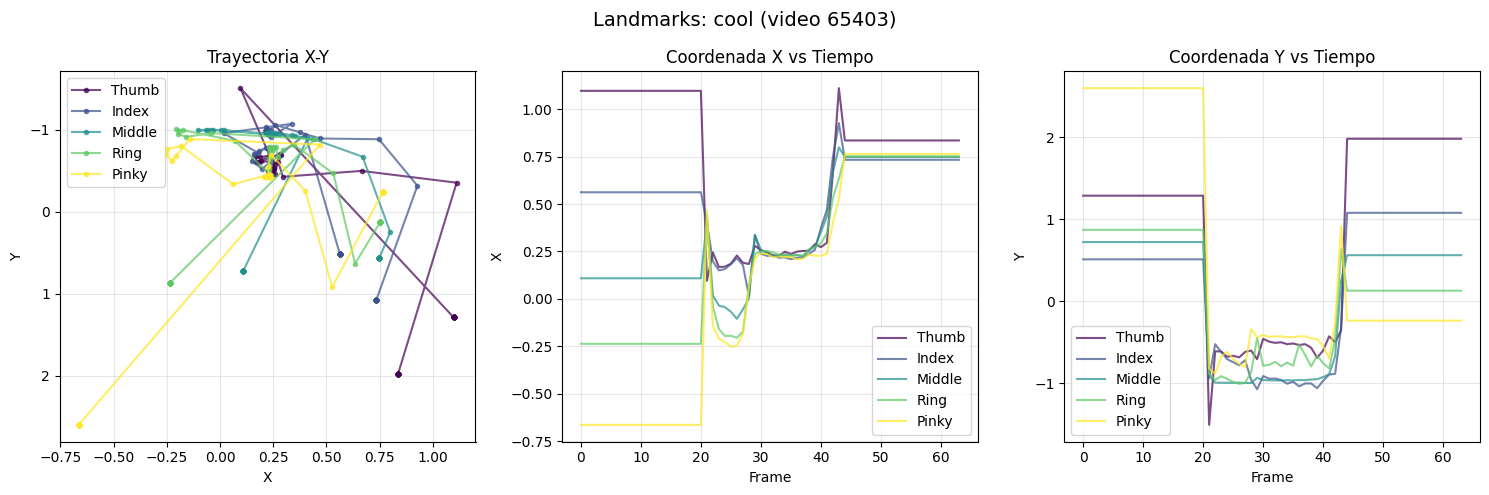

In [14]:
# ==========================================
# 13. VISUALIZACION DE UN EJEMPLO
# ==========================================
import matplotlib.pyplot as plt

# Cargar un ejemplo aleatorio
sample_files = list((OUTPUT_ROOT / 'train').glob('**/*.npy'))
if sample_files:
    sample_path = sample_files[0]
    sample_landmarks = np.load(sample_path)
    
    gloss = sample_path.parent.name
    video_id = sample_path.stem
    
    print(f"Ejemplo: {gloss}/{video_id}")
    print(f"Shape: {sample_landmarks.shape}")
    
    # Visualizar trayectoria de puntas de dedos
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    finger_tips = [4, 8, 12, 16, 20]  # Pulgar, indice, medio, anular, menique
    finger_names = ['Thumb', 'Index', 'Middle', 'Ring', 'Pinky']
    colors = plt.cm.viridis(np.linspace(0, 1, len(finger_tips)))
    
    # X-Y trayectoria
    for idx, (tip, name, color) in enumerate(zip(finger_tips, finger_names, colors)):
        x = sample_landmarks[:, tip, 0]
        y = sample_landmarks[:, tip, 1]
        axes[0].plot(x, y, '-o', label=name, color=color, markersize=3, alpha=0.7)
    axes[0].set_xlabel('X')
    axes[0].set_ylabel('Y')
    axes[0].set_title('Trayectoria X-Y')
    axes[0].legend()
    axes[0].invert_yaxis()
    axes[0].grid(True, alpha=0.3)
    
    # X vs tiempo
    for idx, (tip, name, color) in enumerate(zip(finger_tips, finger_names, colors)):
        x = sample_landmarks[:, tip, 0]
        axes[1].plot(x, label=name, color=color, alpha=0.7)
    axes[1].set_xlabel('Frame')
    axes[1].set_ylabel('X')
    axes[1].set_title('Coordenada X vs Tiempo')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    # Y vs tiempo
    for idx, (tip, name, color) in enumerate(zip(finger_tips, finger_names, colors)):
        y = sample_landmarks[:, tip, 1]
        axes[2].plot(y, label=name, color=color, alpha=0.7)
    axes[2].set_xlabel('Frame')
    axes[2].set_ylabel('Y')
    axes[2].set_title('Coordenada Y vs Tiempo')
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)
    
    plt.suptitle(f'Landmarks: {gloss} (video {video_id})', fontsize=14)
    plt.tight_layout()
    plt.show()
else:
    print("No se encontraron archivos de ejemplo.")

In [15]:
# Liberar recursos
detector.close()
print("\nRecursos de MediaPipe liberados.")
print("\n" + "="*50)
print("NOTEBOOK COMPLETADO")
print("="*50)
print(f"\nLandmarks guardados en: {OUTPUT_ROOT}")
print(f"Listo para entrenar LSTM con landmarks!")


Recursos de MediaPipe liberados.

NOTEBOOK COMPLETADO

Landmarks guardados en: /home/fransando/Dev/tfg-sign-language-recognition/06_datasets/wlasl/landmarks/wlasl30
Listo para entrenar LSTM con landmarks!


## Resumen

Este notebook ha convertido todos los videos de WLASL30 a landmarks de MediaPipe.

### Estructura de salida

```
06_datasets/wlasl/landmarks/wlasl30/
├── metadata.json
├── train/
│   ├── all/
│   │   ├── 12345.npy
│   │   └── ...
│   ├── before/
│   └── ...
├── val/
└── test/
```

### Formato de cada .npy

- Shape: `(T, 21, 3)` donde T <= 64 frames
- 21 landmarks por frame
- 3 coordenadas (x, y, z) por landmark
- Normalizado: centrado en muneca, escalado por distancia al dedo medio

### Proximo paso

Crear notebook `09_lstm_landmarks_training.ipynb` para entrenar un LSTM sobre estos landmarks.